# 📘 3.4 Spline Interpolations

### Smooth interpolation **without** one giant polynomial

In Notebook 3.3, we studied Newton polynomial interpolation.

Newton interpolation is useful and mathematically elegant, but high-degree global polynomials can become sensitive and oscillatory.

Spline interpolation takes a different approach.

Instead of fitting one polynomial across the entire dataset, a spline fits **piecewise polynomials** between neighbouring data points and joins them together smoothly.

This is why splines are widely used for engineering data such as:

* aerodynamic lookup tables,
* stress-strain curves,
* sensor calibration tables,
* vehicle trajectory data,
* CFD or wind tunnel post-processing,
* smooth curves for plotting and analysis.

In this notebook, we will compare linear interpolation, cubic splines, PCHIP interpolation, Akima interpolation, and smoothing splines.

### 🎯 Learning Objectives

By the end of this notebook, you should be able to:

* explain the idea of a spline as a piecewise polynomial;
* distinguish between linear splines, cubic splines, PCHIP and Akima interpolation;
* construct spline interpolants using SciPy;
* explain why boundary conditions matter for cubic splines;
* identify when a spline is performing exact interpolation versus smoothing;
* explain why shape-preserving interpolation can be useful for engineering lookup tables.

### 🔗 Unit Learning Outcome Alignment

This notebook supports the following MMA3001 learning outcomes:

* **LO2:** Demonstrate effective use of numerical analysis and machine learning tools to develop defensible solutions to open-ended engineering problems.
* **LO3:** Apply appropriate mathematical and numerical techniques to solve common engineering problems, and evaluate program performance, error, stability and accuracy.

### 📚 Sources used in this notebook

The main technical ideas in this notebook are based on:

* SciPy API Reference — CubicSpline  
  https://docs.scipy.org/doc/scipy/reference/generated/scipy.interpolate.CubicSpline.html

* SciPy API Reference — PchipInterpolator  
  https://docs.scipy.org/doc/scipy/reference/generated/scipy.interpolate.PchipInterpolator.html

* SciPy API Reference — Akima1DInterpolator  
  https://docs.scipy.org/doc/scipy/reference/generated/scipy.interpolate.Akima1DInterpolator.html

* SciPy User Guide — Smoothing splines  
  https://docs.scipy.org/doc/scipy/tutorial/interpolate/smoothing_splines.html

* Python Numerical Methods — Cubic Spline Interpolation  
  https://pythonnumericalmethods.studentorg.berkeley.edu/notebooks/chapter17.03-Cubic-Spline-Interpolation.html

* Holistic Numerical Methods — Spline Method  
  https://nm.mathforcollege.com/chapter-05-05-spline-method/

* LibreTexts / Autar Kaw — Spline Method of Interpolation  
  https://math.libretexts.org/Workbench/Numerical_Methods_with_Applications_%28Kaw%29/5%3A_Interpolation/5.05%3A_Spline_Method_of_Interpolation

## 📂 3.4.0 How to use this notebook

This is a **pre-work content notebook**. Run every code cell from top to bottom; no cell
requires editing or typed input.  

The separate Week 3 workbook contains the activities to begin in Monday's workshop, continue in Wednesday's practical, and finish during revision at home.


## 📂 3.4.1 What is a spline?

A **spline** is a piecewise polynomial.

Suppose we have data points:

$$
(x_0, y_0), (x_1, y_1), \dots, (x_n, y_n)
$$

A spline defines a separate polynomial on each interval:

$$
[x_0, x_1], [x_1, x_2], \dots, [x_{n-1}, x_n]
$$

For a cubic spline, each interval has a cubic polynomial:

$$
S_i(x)
=
a_i
+
b_i(x - x_i)
+
c_i(x - x_i)^2
+
d_i(x - x_i)^3
$$

for:

$$
x_i \le x \le x_{i+1}
$$

The key idea is that the separate polynomial pieces are joined together **smoothly** at the data points.

The data points where spline pieces meet are often called **knots**.

## 📂 3.4.2 Why use splines instead of one global polynomial?

A global polynomial interpolant uses one polynomial across the full dataset.

A spline uses many lower-degree polynomials.

### Global polynomial interpolation

Advantages:

* one compact mathematical expression;
* passes through the data points;
* useful for theory and some small problems.

Disadvantages:

* can oscillate strongly;
* can be sensitive to data errors;
* one changed point can affect the entire curve;
* high-degree polynomials can behave poorly near the edges.

### Spline interpolation

Advantages:

* uses low-degree polynomial pieces;
* often gives smoother results than linear interpolation;
* avoids many problems of high-degree global polynomials;
* can be designed to preserve shape or monotonicity;
* often works well for engineering lookup tables.

Disadvantages:

* requires choosing a spline type;
* boundary conditions can affect the result;
* exact splines can still overfit noisy data;
* smoothness does not guarantee physical correctness.

### ⚠️ Point of note

A smooth curve is not automatically a good engineering model.

Spline interpolation is still based on assumptions about what happens between measured data points.

## 📂 3.4.3 Types of spline-like interpolation used in this notebook

We will compare four exact interpolation methods.

| Method | Main idea | Smoothness | Typical use |
|---|---|---|---|
| Linear spline | Straight line between points | Continuous, but slope jumps | Simple lookup tables |
| Cubic spline | Piecewise cubic with smooth joins | Continuous first and second derivatives | Smooth engineering curves |
| PCHIP | Shape-preserving piecewise cubic Hermite interpolation | Continuous first derivative | Monotonic or shape-sensitive data |
| Akima | Smooth piecewise cubic based on local slopes | Continuous first derivative | Smooth plotting with local behaviour |

Later, we will also briefly use a **smoothing spline**, which does not necessarily pass through every point.

In [ ]:
from IPython.display import display
# Core imports for this notebook

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.interpolate import (
    CubicSpline,
    PchipInterpolator,
    Akima1DInterpolator,
    make_interp_spline
)

# make_smoothing_spline is the modern SciPy option.
# The fallback keeps the notebook usable on older SciPy versions.
try:
    from scipy.interpolate import make_smoothing_spline
    HAS_MAKE_SMOOTHING_SPLINE = True
except ImportError:
    from scipy.interpolate import UnivariateSpline
    HAS_MAKE_SMOOTHING_SPLINE = False

pd.set_option("display.precision", 5)

## 📂 3.4.4 Example dataset: synthetic airfoil lift table

We will use a small synthetic airfoil-like lookup table.

The independent variable is angle of attack:

$$
\alpha
$$

The dependent variable is lift coefficient:

$$
C_L
$$

The curve increases approximately linearly at low angle of attack, reaches a peak, and then decreases to mimic post-stall behaviour.

### ⚠️ Data note

This is **synthetic teaching data**, not measured wind tunnel data.

It is designed to show interpolation behaviour clearly while keeping the notebook self-contained.

In [ ]:
# Synthetic airfoil-like lookup table

alpha_deg = np.array([-6, -3, 0, 3, 6, 9, 12, 15, 18], dtype=float)

cl_table = np.array([
    -0.58,
    -0.31,
     0.00,
     0.32,
     0.65,
     0.94,
     1.12,
     1.05,
     0.74
], dtype=float)

airfoil_table = pd.DataFrame({
    "alpha_deg": alpha_deg,
    "lift_coefficient_CL": cl_table
})

airfoil_table

,alpha_deg,lift_coefficient_CL
0,-6.0,-0.58
1,-3.0,-0.31
2,0.0,0.00
3,3.0,0.32
4,6.0,0.65
5,9.0,0.94
6,12.0,1.12
7,15.0,1.05
8,18.0,0.74


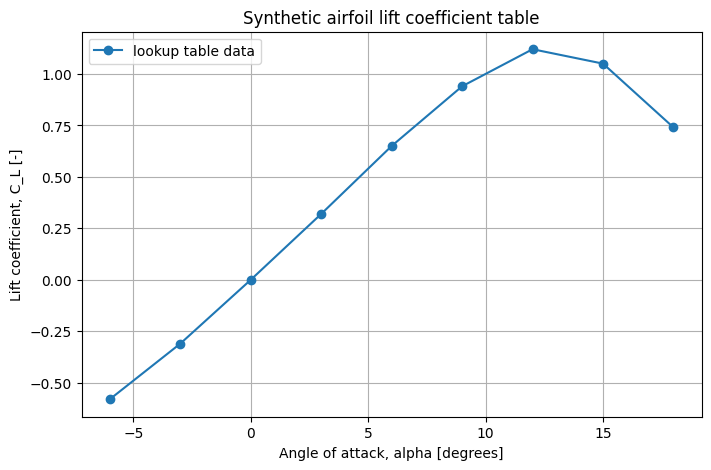

In [ ]:
fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(alpha_deg, cl_table, "o-", label="lookup table data")

ax.set_xlabel("Angle of attack, alpha [degrees]")
ax.set_ylabel("Lift coefficient, C_L [-]")
ax.set_title("Synthetic airfoil lift coefficient table")
ax.grid(True)
ax.legend()

plt.show()

## 📂 3.4.5 Constructing spline interpolants in SciPy

We will build four interpolants:

1. linear spline;
2. cubic spline;
3. PCHIP;
4. Akima.

Each one passes through the original data points.

The difference is how they behave **between** the data points.

In [ ]:
# Evaluation points for smooth plots
alpha_plot = np.linspace(alpha_deg.min(), alpha_deg.max(), 600)

# Linear spline: k=1 gives piecewise linear interpolation.
linear_spline = make_interp_spline(alpha_deg, cl_table, k=1)

# Cubic spline: default boundary condition is not-a-knot.
cubic_spline = CubicSpline(alpha_deg, cl_table, bc_type="not-a-knot")

# PCHIP: shape-preserving cubic Hermite interpolation.
pchip_spline = PchipInterpolator(alpha_deg, cl_table)

# Akima: local-slope-based smooth interpolation.
akima_spline = Akima1DInterpolator(alpha_deg, cl_table)

In [ ]:
query_angles = np.array([-4.5, 2.0, 10.5, 16.5], dtype=float)

comparison_table = pd.DataFrame({
    "alpha_deg": query_angles,
    "linear_CL": linear_spline(query_angles),
    "cubic_spline_CL": cubic_spline(query_angles),
    "pchip_CL": pchip_spline(query_angles),
    "akima_CL": akima_spline(query_angles)
})

comparison_table

,alpha_deg,linear_CL,cubic_spline_CL,pchip_CL,akima_CL
0,-4.5,-0.44500,-0.45261,-0.44983,-0.45150
1,2.0,0.21333,0.21174,0.21223,0.21289
2,10.5,1.03000,1.05341,1.05777,1.05167
3,16.5,0.89500,0.92155,0.93447,0.92469


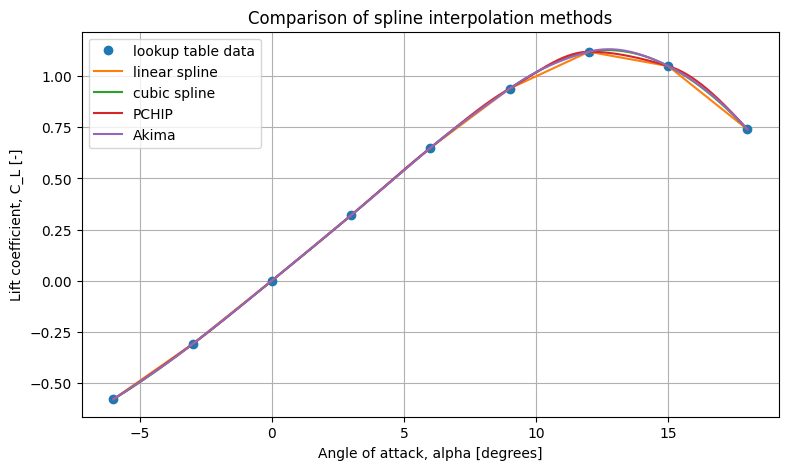

In [ ]:
fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(alpha_deg, cl_table, "o", label="lookup table data")
ax.plot(alpha_plot, linear_spline(alpha_plot), label="linear spline")
ax.plot(alpha_plot, cubic_spline(alpha_plot), label="cubic spline")
ax.plot(alpha_plot, pchip_spline(alpha_plot), label="PCHIP")
ax.plot(alpha_plot, akima_spline(alpha_plot), label="Akima")

ax.set_xlabel("Angle of attack, alpha [degrees]")
ax.set_ylabel("Lift coefficient, C_L [-]")
ax.set_title("Comparison of spline interpolation methods")
ax.grid(True)
ax.legend()

plt.show()

### 🧠 What should you notice?

All four methods pass through the original data points.

However, the curves between the points are different.

The linear spline is simple but has sharp changes in slope at each data point.

The cubic spline is smooth, but it can overshoot or undershoot in some datasets.

PCHIP is often useful when the shape of the data matters, especially when the data is monotonic over part of the domain.

Akima interpolation often gives a visually smooth curve and uses local slope information, but it is still exact interpolation and should be used carefully with noisy data.

## 📂 3.4.6 Checking that exact interpolants pass through the data

For exact interpolation, the interpolated value at each original data point should match the original table value.

We can check this directly.

This is a useful debugging habit.

In [ ]:
node_check = pd.DataFrame({
    "alpha_deg": alpha_deg,
    "original_CL": cl_table,
    "cubic_spline_CL": cubic_spline(alpha_deg),
    "pchip_CL": pchip_spline(alpha_deg),
    "akima_CL": akima_spline(alpha_deg),
    "cubic_error": cubic_spline(alpha_deg) - cl_table,
    "pchip_error": pchip_spline(alpha_deg) - cl_table,
    "akima_error": akima_spline(alpha_deg) - cl_table
})

node_check

,alpha_deg,original_CL,cubic_spline_CL,pchip_CL,akima_CL,cubic_error,pchip_error,akima_error
0,-6.0,-0.58,-0.58,-0.58,-0.58,0.0,0.0,0.0
1,-3.0,-0.31,-0.31,-0.31,-0.31,0.0,0.0,0.0
2,0.0,0.00,0.00,0.00,0.00,0.0,0.0,0.0
3,3.0,0.32,0.32,0.32,0.32,0.0,0.0,0.0
4,6.0,0.65,0.65,0.65,0.65,0.0,0.0,0.0
5,9.0,0.94,0.94,0.94,0.94,0.0,0.0,0.0
6,12.0,1.12,1.12,1.12,1.12,0.0,0.0,0.0
7,15.0,1.05,1.05,1.05,1.05,0.0,0.0,0.0
8,18.0,0.74,0.74,0.74,0.74,0.0,0.0,0.0


In [ ]:
max_cubic_error = np.max(np.abs(node_check["cubic_error"]))
max_pchip_error = np.max(np.abs(node_check["pchip_error"]))
max_akima_error = np.max(np.abs(node_check["akima_error"]))

print(f"Maximum cubic spline error at nodes: {max_cubic_error:.3e}")
print(f"Maximum PCHIP error at nodes:        {max_pchip_error:.3e}")
print(f"Maximum Akima error at nodes:        {max_akima_error:.3e}")

Maximum cubic spline error at nodes: 0.000e+00
Maximum PCHIP error at nodes:        0.000e+00
Maximum Akima error at nodes:        0.000e+00


### 🧩 Code Explanation

The values may not always print as exactly zero because computers use floating-point arithmetic.

Errors around `1e-15` are usually just round-off error.

If the errors are large, check that:

* the input arrays have the same length;
* the `x` values are sorted;
* the `x` values are unique;
* the interpolator was evaluated at the same nodes used to construct it.

## 📂 3.4.7 Smoothness and derivatives

One reason cubic splines are popular is that they are smooth.

For a cubic spline, the function itself, the first derivative and the second derivative are continuous at the knots.

For PCHIP and Akima interpolation, the first derivative is continuous, but the second derivative may not be continuous at the knots.

In engineering, derivative behaviour can matter when the interpolated quantity is later used to estimate:

* slopes,
* rates of change,
* accelerations,
* gradients,
* sensitivity coefficients.

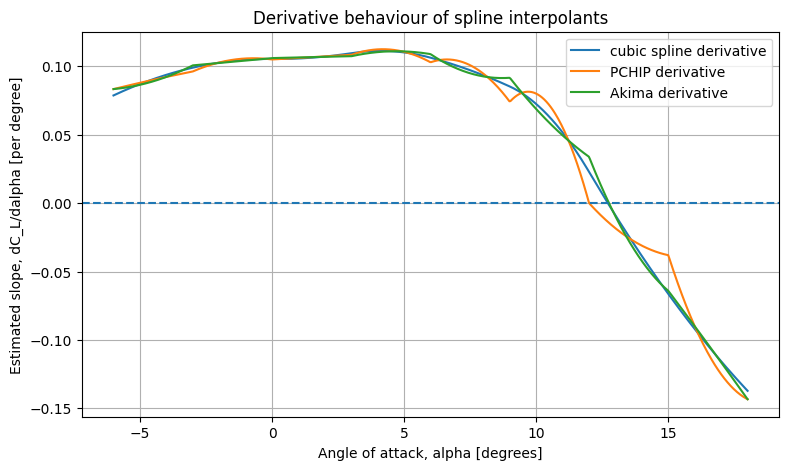

In [ ]:
alpha_derivative_plot = np.linspace(alpha_deg.min(), alpha_deg.max(), 600)

cubic_slope = cubic_spline.derivative(1)(alpha_derivative_plot)
pchip_slope = pchip_spline.derivative(1)(alpha_derivative_plot)
akima_slope = akima_spline.derivative(1)(alpha_derivative_plot)

fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(alpha_derivative_plot, cubic_slope, label="cubic spline derivative")
ax.plot(alpha_derivative_plot, pchip_slope, label="PCHIP derivative")
ax.plot(alpha_derivative_plot, akima_slope, label="Akima derivative")

ax.axhline(0, linestyle="--")

ax.set_xlabel("Angle of attack, alpha [degrees]")
ax.set_ylabel("Estimated slope, dC_L/dalpha [per degree]")
ax.set_title("Derivative behaviour of spline interpolants")
ax.grid(True)
ax.legend()

plt.show()

### 🧠 What should you notice?

The derivative changes sign near the peak lift coefficient.

This corresponds to the transition from increasing lift to decreasing lift.

Different interpolation methods can predict slightly different derivative behaviour.

This matters if you are using the interpolated curve not only to estimate $C_L$, but also to estimate trends or sensitivities.

## 📂 3.4.8 Boundary conditions for cubic splines

A cubic spline needs extra information at the ends of the interval.

This extra information is called the **boundary condition**.

SciPy's `CubicSpline` supports several boundary condition choices.

Common examples are:

| Boundary condition | Meaning |
|---|---|
| `not-a-knot` | Default SciPy choice when no endpoint information is available |
| `natural` | Sets the second derivative to zero at both ends |
| `clamped` | Sets the first derivative to zero at both ends |
| specified end slopes | Sets user-defined first derivatives at the ends |

Boundary conditions mainly affect the curve near the edges of the data range.

### ⚠️ Point of note

Do not choose a boundary condition just because it sounds good.

Choose it because it reflects something you know about the system, or because you have tested that it does not strongly affect the result in the region you care about.

In [ ]:
cubic_not_a_knot = CubicSpline(
    alpha_deg,
    cl_table,
    bc_type="not-a-knot"
)

cubic_natural = CubicSpline(
    alpha_deg,
    cl_table,
    bc_type="natural"
)

# Here we specify illustrative endpoint slopes in units of C_L per degree.
# These are teaching values, not measured airfoil derivatives.
cubic_specified_slopes = CubicSpline(
    alpha_deg,
    cl_table,
    bc_type=((1, 0.10), (1, -0.12))
)

edge_angles = np.array([-5.5, -4.0, 16.0, 17.5], dtype=float)

boundary_table = pd.DataFrame({
    "alpha_deg": edge_angles,
    "not_a_knot_CL": cubic_not_a_knot(edge_angles),
    "natural_CL": cubic_natural(edge_angles),
    "specified_slopes_CL": cubic_specified_slopes(edge_angles)
})

boundary_table

,alpha_deg,not_a_knot_CL,natural_CL,specified_slopes_CL
0,-5.5,-0.53955,-0.53667,-0.53176
1,-4.0,-0.40651,-0.40382,-0.39923
2,16.0,0.97061,0.96454,0.96474
3,17.5,0.80599,0.79949,0.79970


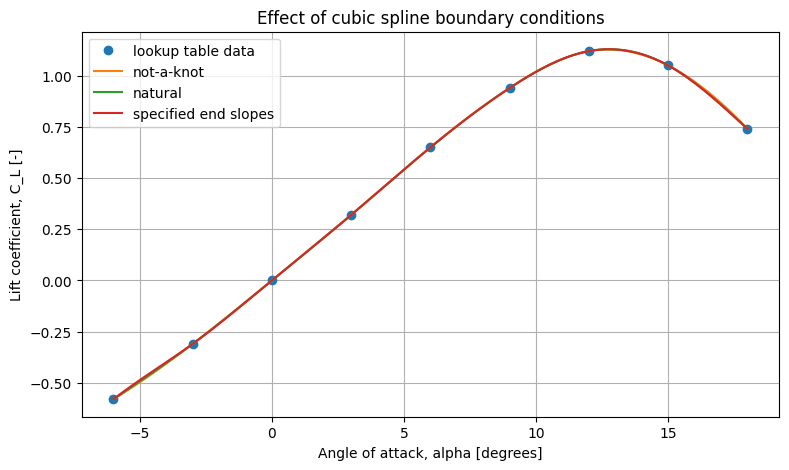

In [ ]:
fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(alpha_deg, cl_table, "o", label="lookup table data")
ax.plot(alpha_plot, cubic_not_a_knot(alpha_plot), label="not-a-knot")
ax.plot(alpha_plot, cubic_natural(alpha_plot), label="natural")
ax.plot(alpha_plot, cubic_specified_slopes(alpha_plot), label="specified end slopes")

ax.set_xlabel("Angle of attack, alpha [degrees]")
ax.set_ylabel("Lift coefficient, C_L [-]")
ax.set_title("Effect of cubic spline boundary conditions")
ax.grid(True)
ax.legend()

plt.show()

### 🧠 What should you notice?

The boundary conditions can change the curve near the ends of the data range.

The differences may be small or large depending on the dataset.

This is especially important when:

* you are interpolating close to the edge of the data;
* you need derivative estimates;
* the endpoint physics is known;
* the data has few points;
* the curve will be used inside a larger engineering calculation.

## 📂 3.4.9 Shape preservation and overshoot

A cubic spline is very smooth, but smoothness is not always the most important goal.

For some engineering tables, it is more important that the interpolated curve preserves the shape of the data.

For example:

* a calibration curve should not create artificial local peaks;
* a monotonic lookup table should usually remain monotonic;
* a physical quantity that cannot go negative should not become negative between positive data points;
* an interpolated pressure, density, or efficiency curve should not create unrealistic intermediate behaviour.

PCHIP is often a good choice when preserving the shape of the data is important.

In [ ]:
method_range_table = pd.DataFrame({
    "method": ["data", "linear", "cubic spline", "PCHIP", "Akima"],
    "minimum_CL": [
        np.min(cl_table),
        np.min(linear_spline(alpha_plot)),
        np.min(cubic_spline(alpha_plot)),
        np.min(pchip_spline(alpha_plot)),
        np.min(akima_spline(alpha_plot))
    ],
    "maximum_CL": [
        np.max(cl_table),
        np.max(linear_spline(alpha_plot)),
        np.max(cubic_spline(alpha_plot)),
        np.max(pchip_spline(alpha_plot)),
        np.max(akima_spline(alpha_plot))
    ]
})

method_range_table

,method,minimum_CL,maximum_CL
0,data,-0.58,1.12000
1,linear,-0.58,1.11940
2,cubic spline,-0.58,1.12804
3,PCHIP,-0.58,1.12000
4,Akima,-0.58,1.13235


### 🧠 Interpretation

Compare the minimum and maximum values produced by each interpolation method.

If an interpolant creates values outside the range suggested by the data, that may or may not be acceptable.

It depends on the physical system.

For example, a small overshoot near the maximum lift coefficient might be unacceptable if the data is being used for a conservative stall margin estimate.

### ⚠️ Engineering warning

Interpolation is not only about making a curve look smooth.

It is about making a defensible assumption between known data points.

## 📂 3.4.10 Handling extrapolation with splines

Spline functions can produce values outside the data range if extrapolation is enabled.

As discussed in Notebook 3.1, extrapolation should be treated with caution.

One useful option is to disable extrapolation so that out-of-range predictions return `NaN`.

This makes extrapolation easier to detect.

In [ ]:
safe_cubic_spline = CubicSpline(
    alpha_deg,
    cl_table,
    extrapolate=False
)

check_angles = np.array([-8.0, 0.0, 20.0], dtype=float)

safe_table = pd.DataFrame({
    "alpha_deg": check_angles,
    "prediction_CL": safe_cubic_spline(check_angles)
})

safe_table

,alpha_deg,prediction_CL
0,-8.0,NaN
1,0.0,0.0
2,20.0,NaN


### 🧠 What should you notice?

The prediction at $0^\circ$ is inside the data range, so it returns a value.

The predictions at $-8^\circ$ and $20^\circ$ are outside the data range, so they return `NaN`.

This is useful because it prevents extrapolated values from silently entering an engineering calculation.

## 📂 3.4.11 Smoothing splines for noisy data

So far, the spline methods have performed **exact interpolation**.

That means they pass through every data point.

But as we saw in Notebook 3.2, exact interpolation can be a bad idea when the data is noisy.

A **smoothing spline** does not necessarily pass through every point.

Instead, it balances two goals:

1. stay close to the measured data;
2. avoid excessive curvature or unnecessary wiggles.

This makes smoothing splines useful for noisy experimental data.

### ⚠️ Point of note

Smoothing is not interpolation.

Smoothing is a form of approximation.

In [ ]:
def true_pressure_coefficient(x_over_c):
    """
    Synthetic pressure coefficient trend.

    This is teaching data, not measured airfoil pressure data.
    """
    x_over_c = np.asarray(x_over_c, dtype=float)

    return 1.2 - 0.8 * x_over_c + 0.15 * np.sin(2 * np.pi * x_over_c)


rng = np.random.default_rng(7)

x_sensor = np.linspace(0, 1, 25)
noise_std = 0.035

cp_true = true_pressure_coefficient(x_sensor)
cp_measured = cp_true + rng.normal(0, noise_std, size=x_sensor.size)

pressure_data = pd.DataFrame({
    "x_over_c": x_sensor,
    "cp_measured": cp_measured,
    "cp_true_for_teaching_only": cp_true
})

pressure_data.head()

,x_over_c,cp_measured,cp_true_for_teaching_only
0,0.00000,1.20004,1.20000
1,0.04167,1.21595,1.20549
2,0.08333,1.19874,1.20833
3,0.12500,1.17490,1.20607
4,0.16667,1.18066,1.19657


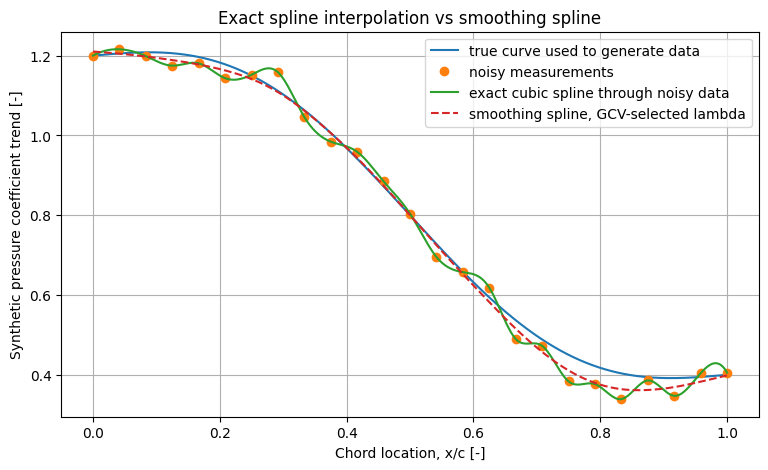

In [ ]:
x_dense = np.linspace(0, 1, 500)

exact_spline_noisy = CubicSpline(x_sensor, cp_measured)

if HAS_MAKE_SMOOTHING_SPLINE:
    smooth_spline = make_smoothing_spline(x_sensor, cp_measured, lam=None)
    smoothing_method_label = "smoothing spline, GCV-selected lambda"
else:
    smoothing_factor = len(x_sensor) * noise_std**2
    smooth_spline = UnivariateSpline(x_sensor, cp_measured, k=3, s=smoothing_factor)
    smoothing_method_label = "smoothing spline, fallback method"

fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(x_dense, true_pressure_coefficient(x_dense), label="true curve used to generate data")
ax.plot(x_sensor, cp_measured, "o", label="noisy measurements")
ax.plot(x_dense, exact_spline_noisy(x_dense), label="exact cubic spline through noisy data")
ax.plot(x_dense, smooth_spline(x_dense), "--", label=smoothing_method_label)

ax.set_xlabel("Chord location, x/c [-]")
ax.set_ylabel("Synthetic pressure coefficient trend [-]")
ax.set_title("Exact spline interpolation vs smoothing spline")
ax.grid(True)
ax.legend()

plt.show()

In [ ]:
def rmse(y_true, y_pred):
    """
    Root mean squared error.
    """
    return np.sqrt(np.mean((y_true - y_pred) ** 2))


rmse_table = pd.DataFrame({
    "method": [
        "exact cubic spline",
        smoothing_method_label
    ],
    "RMSE_against_teaching_true_curve": [
        rmse(true_pressure_coefficient(x_dense), exact_spline_noisy(x_dense)),
        rmse(true_pressure_coefficient(x_dense), smooth_spline(x_dense))
    ]
})

rmse_table

,method,RMSE_against_teaching_true_curve
0,exact cubic spline,0.02992
1,"smoothing spline, GCV-selected lambda",0.01965


### 🧠 What should you notice?

The exact cubic spline passes through every noisy measurement.

The smoothing spline does not necessarily pass through every measurement.

In this synthetic example, we know the true curve, so we can compare both methods directly.

In a real experiment, the true curve is unknown. You would need to use repeated measurements, validation data, physical reasoning, or uncertainty analysis to judge whether the smoothing is appropriate.

### ⚠️ Engineering warning

A smoothing spline can also be wrong.

Too little smoothing can preserve noise.

Too much smoothing can remove real physical behaviour.

## 📂 3.4.12 Worked extension — choose an interpolation method

Choose one interpolation method and evaluate it at three angles of attack.

Suggested methods are:

* `linear`
* `cubic`
* `pchip`
* `akima`

### Questions

1. Which method did you choose?
2. Why might that method be appropriate?
3. Are all your query angles inside the original data range?
4. How different are your predictions from the other methods?

In [ ]:
# Demonstration setting: Change the method name and query angles.

student_method_name = "pchip"

student_query_angles = np.array([
    -2.0,
    7.5,
    13.5
], dtype=float)

if student_method_name == "linear":
    student_model = linear_spline
elif student_method_name == "cubic":
    student_model = cubic_spline
elif student_method_name == "pchip":
    student_model = pchip_spline
elif student_method_name == "akima":
    student_model = akima_spline
else:
    raise ValueError("student_method_name must be one of: linear, cubic, pchip, akima")

student_results = pd.DataFrame({
    "alpha_deg": student_query_angles,
    "predicted_CL": student_model(student_query_angles)
})

student_results

,alpha_deg,predicted_CL
0,-2.0,-0.21020
1,7.5,0.80582
2,13.5,1.09928


## 📂 3.4.13 Worked extension — investigate boundary conditions

Change `student_boundary_type` to one of:

* `not-a-knot`
* `natural`
* `clamped`

Then rerun the cell.

### Questions

1. Which boundary condition did you choose?
2. Did it change the curve near the edges?
3. Did it change the curve near the middle?
4. Would you use this boundary condition in a real engineering calculation? Why or why not?

In [ ]:
# Demonstration setting: Try "not-a-knot", "natural", and "clamped".

student_boundary_type = "natural"

student_cubic = CubicSpline(
    alpha_deg,
    cl_table,
    bc_type=student_boundary_type
)

student_edge_angles = np.array([-5.5, 0.0, 17.5], dtype=float)

student_boundary_results = pd.DataFrame({
    "alpha_deg": student_edge_angles,
    "predicted_CL": student_cubic(student_edge_angles)
})

student_boundary_results

,alpha_deg,predicted_CL
0,-5.5,-0.53667
1,0.0,0.00000
2,17.5,0.79949


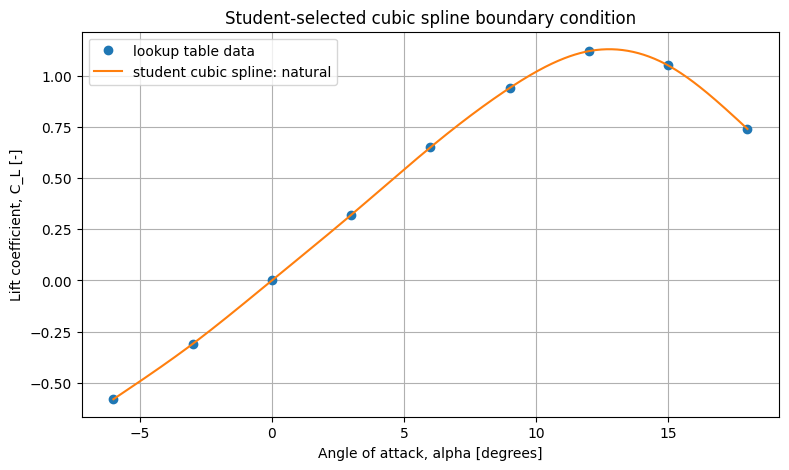

In [ ]:
fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(alpha_deg, cl_table, "o", label="lookup table data")
ax.plot(alpha_plot, student_cubic(alpha_plot), label=f"student cubic spline: {student_boundary_type}")

ax.set_xlabel("Angle of attack, alpha [degrees]")
ax.set_ylabel("Lift coefficient, C_L [-]")
ax.set_title("Student-selected cubic spline boundary condition")
ax.grid(True)
ax.legend()

plt.show()

## 📂 3.4.14 Worked extension — smoothing noisy data

Change the smoothing settings and observe the result.

If your SciPy version supports `make_smoothing_spline`, change `student_lam`.

Try values such as `None`, `0.0`, `0.001`, `0.01`, and `0.1`.

If your notebook uses the fallback method, change `student_s`.

### Questions

1. What happens when there is very little smoothing?
2. What happens when there is too much smoothing?
3. Which setting looks most reasonable for this dataset?
4. Why is it dangerous to choose a smoothing setting based only on appearance?

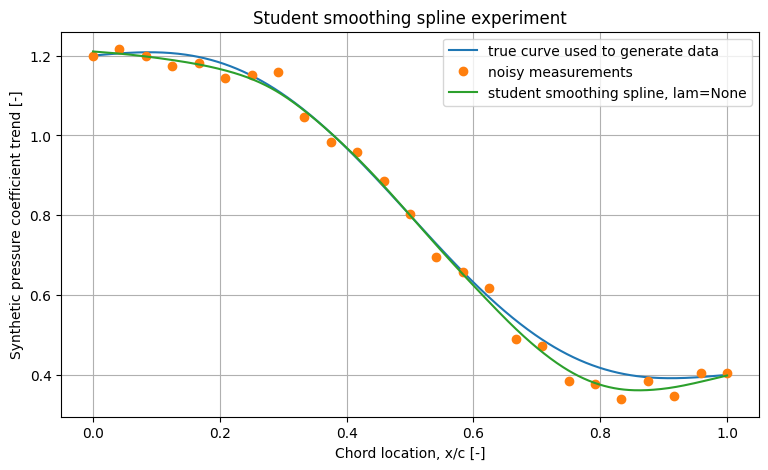

In [ ]:
# Demonstration setting: Modify these settings and rerun the cell.
# For make_smoothing_spline, student_lam controls the smoothness penalty.
# For the fallback method, student_s controls the smoothing factor.

student_lam = None
student_s = len(x_sensor) * noise_std**2

if HAS_MAKE_SMOOTHING_SPLINE:
    student_smooth_spline = make_smoothing_spline(
        x_sensor,
        cp_measured,
        lam=student_lam
    )
    student_label = f"student smoothing spline, lam={student_lam}"
else:
    student_smooth_spline = UnivariateSpline(
        x_sensor,
        cp_measured,
        k=3,
        s=student_s
    )
    student_label = f"student smoothing spline, s={student_s:.4f}"

fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(x_dense, true_pressure_coefficient(x_dense), label="true curve used to generate data")
ax.plot(x_sensor, cp_measured, "o", label="noisy measurements")
ax.plot(x_dense, student_smooth_spline(x_dense), label=student_label)

ax.set_xlabel("Chord location, x/c [-]")
ax.set_ylabel("Synthetic pressure coefficient trend [-]")
ax.set_title("Student smoothing spline experiment")
ax.grid(True)
ax.legend()

plt.show()

## 📂 3.4.15 Recommended resources

### Reading

* SciPy API Reference — CubicSpline  
  https://docs.scipy.org/doc/scipy/reference/generated/scipy.interpolate.CubicSpline.html

* SciPy API Reference — PchipInterpolator  
  https://docs.scipy.org/doc/scipy/reference/generated/scipy.interpolate.PchipInterpolator.html

* SciPy API Reference — Akima1DInterpolator  
  https://docs.scipy.org/doc/scipy/reference/generated/scipy.interpolate.Akima1DInterpolator.html

* SciPy User Guide — Smoothing splines  
  https://docs.scipy.org/doc/scipy/tutorial/interpolate/smoothing_splines.html

* Python Numerical Methods — Cubic Spline Interpolation  
  https://pythonnumericalmethods.studentorg.berkeley.edu/notebooks/chapter17.03-Cubic-Spline-Interpolation.html

* Holistic Numerical Methods — Spline Method  
  https://nm.mathforcollege.com/chapter-05-05-spline-method/

### Videos

* Holistic Numerical Methods — Spline Method video resources  
  https://nm.mathforcollege.com/chapter-05-05-spline-method/

* Search topic: cubic spline interpolation numerical methods  
  https://www.youtube.com/results?search_query=cubic+spline+interpolation+numerical+methods

## 📂 3.4.16 Engineering workflow and summary

When selecting a spline method, begin by considering the data and the intended engineering use.

- Use a **linear spline** when simplicity and local behaviour are more important than smooth derivatives.
- Use a **cubic spline** when a smooth curve and continuous first and second derivatives are important.
- Use **PCHIP** when preserving monotonicity and avoiding artificial overshoot are important.
- Use **Akima interpolation** when a local, visually smooth interpolant is useful, while remembering that it still passes through every data point.
- Use a **smoothing spline** when the observations contain noise and exact interpolation is not justified.

The main lessons from this notebook are:

- a spline is a piecewise-polynomial model joined at data nodes;

- different spline methods can pass through the same data while behaving differently between the nodes;

- cubic-spline boundary conditions affect the curve, particularly near the ends of the data domain;

- a visually smooth curve is not necessarily physically correct;

- shape preservation may be more important than maximum smoothness;

- exact interpolation should be used carefully when data contains measurement noise;

- extrapolation should be disabled or clearly flagged when it is unsupported;

- method selection should consider the required values, slopes, curvature, locality, and physical constraints.

- Choose a spline because its mathematical behaviour suits the engineering problem, not simply because its curve looks smooth.

### 📚 Current software documentation checked

The implementation guidance in this notebook was checked against the current stable
documentation on 25 July 2026:

* SciPy 1.17 interpolation guide: https://docs.scipy.org/doc/scipy/tutorial/interpolate.html
* SciPy interpolation API: https://docs.scipy.org/doc/scipy/reference/interpolate.html
* scikit-learn 1.9 documentation (where used): https://scikit-learn.org/stable/


## 📚 References

1. SciPy Developers, `scipy.interpolate.CubicSpline`.  
   https://docs.scipy.org/doc/scipy/reference/generated/scipy.interpolate.CubicSpline.html

2. SciPy Developers, `scipy.interpolate.PchipInterpolator`.  
   https://docs.scipy.org/doc/scipy/reference/generated/scipy.interpolate.PchipInterpolator.html

3. SciPy Developers, `scipy.interpolate.Akima1DInterpolator`.  
   https://docs.scipy.org/doc/scipy/reference/generated/scipy.interpolate.Akima1DInterpolator.html

4. SciPy User Guide, Smoothing splines.  
   https://docs.scipy.org/doc/scipy/tutorial/interpolate/smoothing_splines.html

5. Kong, Q., Siauw, T., Bayen, A. M., Python Numerical Methods: A Guide for Engineers and Scientists, Cubic Spline Interpolation.  
   https://pythonnumericalmethods.studentorg.berkeley.edu/notebooks/chapter17.03-Cubic-Spline-Interpolation.html

6. Holistic Numerical Methods, Chapter 05.05 Spline Method.  
   https://nm.mathforcollege.com/chapter-05-05-spline-method/

7. Kaw, A., Numerical Methods with Applications, LibreTexts, Spline Method of Interpolation.  
   https://math.libretexts.org/Workbench/Numerical_Methods_with_Applications_%28Kaw%29/5%3A_Interpolation/5.05%3A_Spline_Method_of_Interpolation

## 🤖 AI Acknowledgment

Parts of this notebook were developed with the assistance of AI tools for drafting explanations, code structure, and student prompts.

All technical content, code, references, and examples have been reviewed and adapted for MMA3001 teaching purposes.

Students should treat AI-generated explanations and code as starting points only. Numerical outputs should be checked using plots, tests, documentation, and engineering judgement.